# Part 1 — The science, then the server

This notebook walks through the **spectra-mcp-server** repo in three steps:

1. **The science by hand** — load the eBOSS DR14 Lyman-α data and compute matter
   power spectra with CLASS, calling plain Python functions.
2. **The same science as *tools*** — the four functions in `tools/spectra_tools.py`
   that agents will call. They are still plain Python: you can run them right here.
3. **The MCP server** — how ~70 lines in `mcp_server/` turn those functions into a
   server any agent can connect to.

The punchline of the repo layout: **the science code never imports MCP.**
The wrapper finds the tools by reading `__all__` from the package listed in
`pyproject.toml` under `[tool.mcp-server]`.

## 1. The observational data

eBOSS DR14 Lyman-α forest power spectrum: 19 bins of $(k, P(k), \sigma_P)$,
bundled in `data/DR14_pm3d_19kbins.txt`. The file comes verbatim from the
[Chabanier+2019 compilation](https://github.com/marius311/mpk_compilation) —
it is the **z = 0 linear** matter power inferred from the Ly-α forest, so it
should lie *on* the ΛCDM curve.

> **Units gotcha** (a real bug we inherited and fixed): the file's k column is
> in **1/Mpc** while P(k) is in **(Mpc/h)³** — the source notebook plots
> `errorbar(k/h, Pk)`. Read k as h/Mpc and the data lands a factor ~2 below
> theory, which an earlier version of this demo mistook for "bias factors".
> Moral: when you bundle someone's data file, read the code that plots it.
> `load_eboss_arrays()` now does the `k/h` conversion in exactly one place.

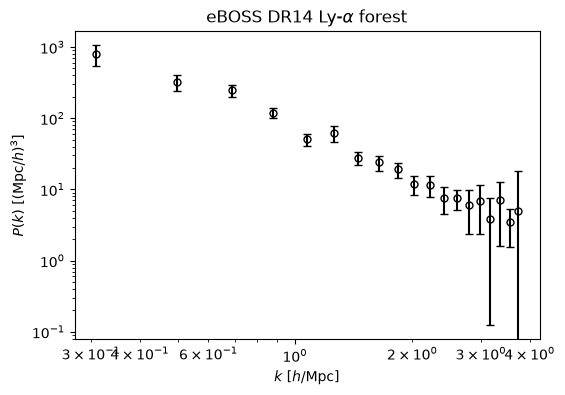

In [1]:
import sys
from pathlib import Path

sys.path.insert(0, str(Path.cwd().parent))  # repo root, so `import tools` works

import matplotlib.pyplot as plt
import numpy as np

from tools.spectra_tools import load_eboss_arrays

k_obs, pk_obs, sigma_obs = load_eboss_arrays()

fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(k_obs, pk_obs, yerr=sigma_obs, fmt="ko", markersize=5,
            markerfacecolor="none", capsize=3)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel(r"$k\ [h/\mathrm{Mpc}]$")
ax.set_ylabel(r"$P(k)\ [(\mathrm{Mpc}/h)^3]$")
ax.set_title("eBOSS DR14 Ly-$\\alpha$ forest")
plt.show()

## 2. The science by hand

`tools/cosmology.py` defines three cosmologies as CLASS parameter dictionaries
(Planck 2018 baseline) plus one function, `run_class`, that computes $P(k)$:

- **lcdm** — flat ΛCDM baseline
- **nu_mass** — ΛCDM + massive neutrinos (free-streaming suppresses small-scale power)
- **wcdm** — constant-$w$ dark energy fluid (alters late-time growth)

No agents, no MCP — just calling functions.

In [2]:
from tools.cosmology import lcdm, nu_mass, wcdm, run_class

k = np.logspace(-3, np.log10(4.0), 200)  # h/Mpc

spectra_by_label = {
    "LCDM": run_class(lcdm(), k),
    "LCDM + massive nu (0.1 eV)": run_class(nu_mass(0.10), k),
    "wCDM (w0 = -0.9)": run_class(wcdm(-0.9), k),
}

for label, pk in spectra_by_label.items():
    ratio_at_1 = pk[np.argmin(np.abs(k - 1.0))] / spectra_by_label["LCDM"][np.argmin(np.abs(k - 1.0))]
    print(f"{label:35s} P(k=1)/P_LCDM(k=1) = {ratio_at_1:.3f}")

LCDM                                P(k=1)/P_LCDM(k=1) = 1.000
LCDM + massive nu (0.1 eV)          P(k=1)/P_LCDM(k=1) = 0.948
wCDM (w0 = -0.9)                    P(k=1)/P_LCDM(k=1) = 0.946


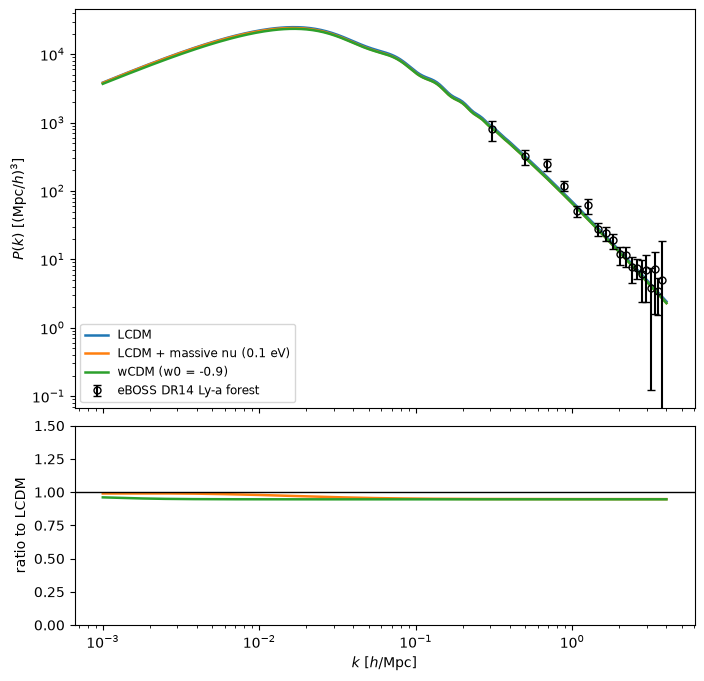

In [3]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 8), sharex=True,
                               gridspec_kw={"height_ratios": [2, 1], "hspace": 0.06})
for i, (label, pk) in enumerate(spectra_by_label.items()):
    ax1.loglog(k, pk, color=f"C{i}", linewidth=1.8, label=label)
ax1.errorbar(k_obs, pk_obs, yerr=sigma_obs, fmt="ko", markersize=5,
             markerfacecolor="none", capsize=3, label="eBOSS DR14 Ly-a forest")
ax1.set_ylabel(r"$P(k)\ [(\mathrm{Mpc}/h)^3]$"); ax1.legend(loc="lower left", fontsize="small")

pk_ref = spectra_by_label["LCDM"]
for i, (label, pk) in enumerate(spectra_by_label.items()):
    if label != "LCDM":
        ax2.semilogx(k, pk / pk_ref, color=f"C{i}", linewidth=1.8)
ax2.axhline(1.0, color="black", linewidth=1)
ax2.set_xlabel(r"$k\ [h/\mathrm{Mpc}]$"); ax2.set_ylabel("ratio to LCDM"); ax2.set_ylim(0, 1.5)
plt.show()

The data scatters around the ΛCDM curve within its error bars (χ²/N ≈ 0.5) —
as it must, since these points are the *inferred z=0 linear matter power*.
The three models differ by only a few percent here; distinguishing them is why
the ratio panel exists.

## 3. The same science as tools

`tools/spectra_tools.py` wraps the pipeline above into **four functions** with
Pydantic-validated signatures and agent-facing docstrings. Two design rules:

- Every tool returns the same `ArtifactResult` contract:
  `{status, files, message, metadata}`.
- Arrays move between tools **as CSV file paths**, never through the agent's
  context window. `compute_power_spectrum` writes `pk_<model>.csv`;
  `plot_power_spectra` reads those files back.

They are still ordinary Python — call them right here, no server involved.

In [4]:
from tools import (get_eboss_data, list_cosmology_models,
                     compute_power_spectrum, plot_power_spectra)

print(get_eboss_data().message)

models = list_cosmology_models()
print(models.message)
for name, info in models.metadata["models"].items():
    print(f"  {name:8s} — {info['description']}")

Loaded 19 eBOSS DR14 Ly-a P(k) bins.
3 models available: lcdm, nu_mass, wcdm.
  lcdm     — Flat LCDM baseline (Planck 2018, w = -1).
  nu_mass  — LCDM plus massive neutrinos; suppresses small-scale power.
  wcdm     — Constant-w dark energy fluid; alters late-time growth.


Computed P(k) for LCDM at z=0 (200 points). -> /Users/nesar/Projects/Tutorials/spectra-mcp-server/notebooks/output/pk_lcdm.csv
Computed P(k) for LCDM + massive nu (0.1 eV) at z=0 (200 points). -> /Users/nesar/Projects/Tutorials/spectra-mcp-server/notebooks/output/pk_nu_mass.csv


Computed P(k) for wCDM (w0 = -0.9) at z=0 (200 points). -> /Users/nesar/Projects/Tutorials/spectra-mcp-server/notebooks/output/pk_wcdm.csv


Plotted 3 spectra against eBOSS DR14 Ly-a forest.


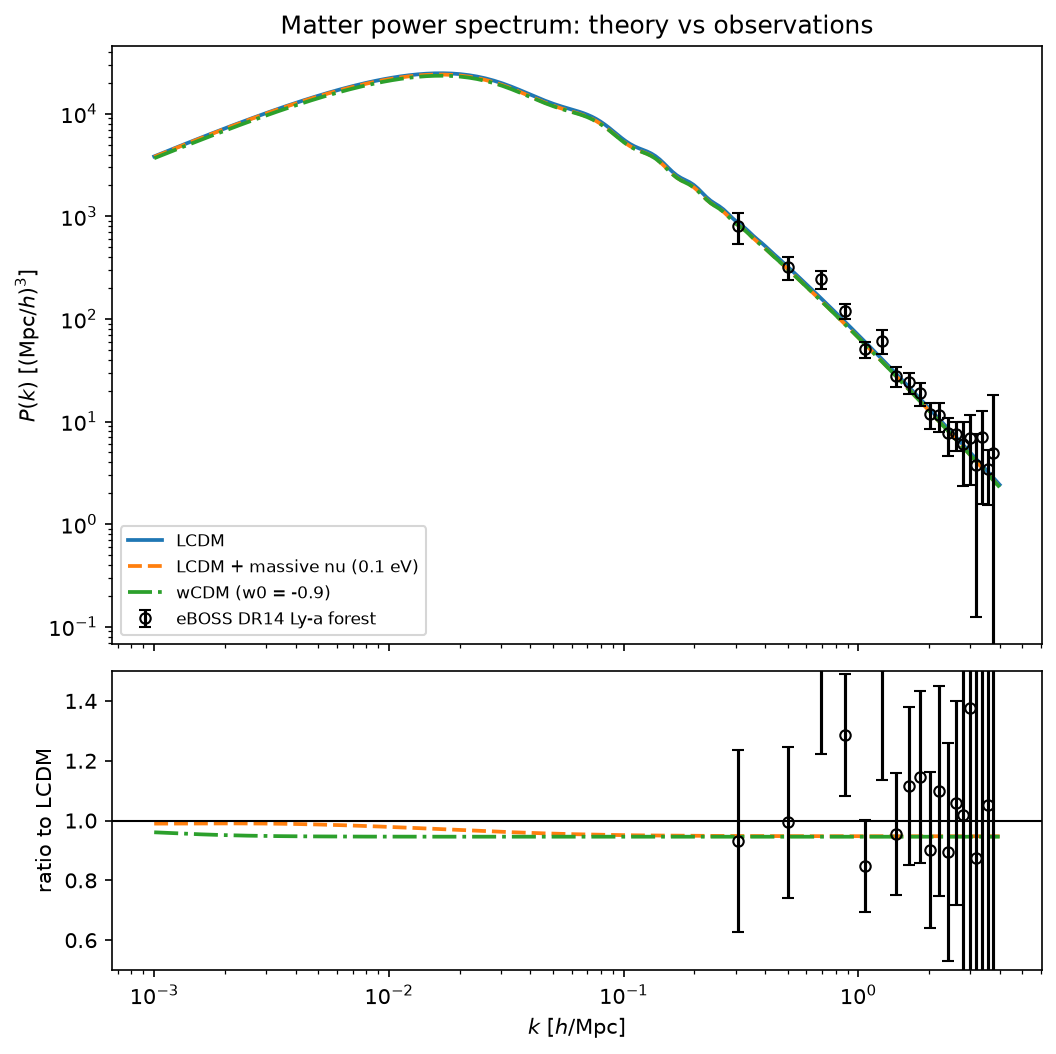

In [5]:
OUTPUT_DIR = "output"

spectrum_files = []
for model in ["lcdm", "nu_mass", "wcdm"]:
    result = compute_power_spectrum(model=model, output_dir=OUTPUT_DIR)
    print(result.message, "->", result.files[0])
    spectrum_files.append(result.files[0])

plot_result = plot_power_spectra(spectrum_files=spectrum_files, output_dir=OUTPUT_DIR)
print(plot_result.message)

from IPython.display import Image
Image(plot_result.files[0])

This figure is the **ground truth** for Part 2: the multi-agent client will be asked
to reproduce it by calling these same tools over the network.

## 4. From functions to MCP server

`mcp_server/` is a generic, drop-in wrapper (~70 lines). It:

1. finds `pyproject.toml` and reads `[tool.mcp-server] tool_modules = ["tools"]`,
2. imports that package,
3. registers every function named in its `__all__` with **FastMCP**.

The type hints, `Field` constraints, and docstrings you saw above become the JSON
schema that agents see. Let's build the server in-process and inspect it:

In [6]:
import json
from mcp_server import create_server

server = create_server()
tools = await server.list_tools()

print("Tools exposed:", [t.name for t in tools], "\n")
schema = next(t for t in tools if t.name == "compute_power_spectrum")
print(json.dumps(schema.inputSchema, indent=2)[:900])

Tools exposed: ['get_eboss_data', 'list_cosmology_models', 'compute_power_spectrum', 'plot_power_spectra'] 

{
  "properties": {
    "model": {
      "enum": [
        "lcdm",
        "nu_mass",
        "wcdm"
      ],
      "title": "Model",
      "type": "string"
    },
    "output_dir": {
      "minLength": 1,
      "title": "Output Dir",
      "type": "string"
    },
    "sum_mnu_eV": {
      "default": 0.1,
      "exclusiveMinimum": 0,
      "maximum": 1.0,
      "title": "Sum Mnu Ev",
      "type": "number"
    },
    "w0": {
      "default": -0.9,
      "maximum": -0.3,
      "minimum": -2.0,
      "title": "W0",
      "type": "number"
    },
    "k_min": {
      "default": 0.001,
      "exclusiveMinimum": 0.0001,
      "title": "K Min",
      "type": "number"
    },
    "k_max": {
      "default": 4.0,
      "maximum": 10.0,
      "title": "K Max",
      "type": "number"
    },
    "n_points": {
      "default": 200,
      "maximum": 1000,
      "minimum": 10,
      "title": "N

/Users/nesar/anaconda3/envs/spectra-tutorial/lib/python3.12/site-packages/pydantic_settings/sources/utils.py:47: IncompleteFieldDefinitionWarning: Field 'lifespan' has an incomplete definition: its annotation contains an unresolved forward reference, so settings sources may fail to correctly resolve its value. Call `model_rebuild()` on the model where the field is defined, once all the referenced types are defined.
  warnings.warn(


## 5. Run it for real

**Streamable HTTP** (what Part 2 uses first) — run in a terminal from the repo root:

```bash
python -m mcp_server --transport streamable-http --port 8000
```

The server is now a URL: `http://127.0.0.1:8000/mcp`. Any MCP client can connect:

```python
{"spectra": {"transport": "streamable_http", "url": "http://127.0.0.1:8000/mcp"}}
```

**stdio** (what production MCP clients like Claude Desktop use) — do **not** start it
yourself; the *client* spawns the server as a subprocess:

```python
{"spectra": {"transport": "stdio", "command": "python",
             "args": ["-m", "mcp_server"], "cwd": "<this repo>"}}
```

> Watch the naming tripwire: the server CLI spells it `streamable-http` (hyphen),
> most Python clients spell it `streamable_http` (underscore).

## Where to go next

- **Part 2** — [`multiagent-client-demo`](https://github.com/HEP-KE/multiagent-client-demo):
  a small LangGraph multi-agent client that connects to this server and reproduces
  the figure above from a one-sentence science question.
- **Make it yours** — add your own module next to `tools/spectra_tools.py`, list its
  functions in `__all__`, and they become MCP tools with zero wrapper changes. The
  same pattern scales to servers with dozens of tools (MCMC pipelines, literature
  search, instrument control...).